In [1]:
import pandas as pd

df = pd.read_csv("data/ecommerce_cleaned.csv", low_memory=False)

print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

df.head()

Dataset Shape: (530104, 9)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [2]:
import pandas as pd

df = pd.read_csv("data/ecommerce_cleaned.csv", low_memory=False)

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

df.head()

Dataset Shape: (530104, 9)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [3]:
# Check data types and missing values
print("Dataset Information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 530104 entries, 0 to 530103
Data columns (total 9 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    530104 non-null  str    
 1   StockCode    530104 non-null  str    
 2   Description  530104 non-null  str    
 3   Quantity     530104 non-null  int64  
 4   InvoiceDate  530104 non-null  str    
 5   UnitPrice    530104 non-null  float64
 6   CustomerID   397884 non-null  float64
 7   Country      530104 non-null  str    
 8   Revenue      530104 non-null  float64
dtypes: float64(3), int64(1), str(5)
memory usage: 71.9 MB

Missing values in each column:
InvoiceNo           0
StockCode           0
Description         0
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     132220
Country             0
Revenue             0
dtype: int64

Duplicate rows: 5226


In [6]:
print("Missing CID:", df["CustomerID"].isnull().sum())
print("Total rows:", len(df))
print("Missing CID rows ka revenue:",
      (df.loc[df["CustomerID"].isnull(), "Quantity"] *
       df.loc[df["CustomerID"].isnull(), "UnitPrice"]).sum())

Missing CID: 132220
Total rows: 530104
Missing CID rows ka revenue: 1755276.6400000001


In [7]:
# Create a separate copy for ML
ml_df = df.copy()

# Keep only rows with a valid Customer ID for customer-based ML
ml_df = ml_df.dropna(subset=["CustomerID"]).copy()

print("Original rows:", len(df))
print("Rows for customer-based ML:", len(ml_df))
print("Missing CustomerID after cleaning:",
      ml_df["CustomerID"].isnull().sum())

Original rows: 530104
Rows for customer-based ML: 397884
Missing CustomerID after cleaning: 0


In [5]:
print("All columns:")
for col in df.columns:
    print(col)
    df.head(3)

All columns:
InvoiceNo
StockCode
Description
Quantity
InvoiceDate
UnitPrice
CustomerID
Country
Revenue


In [8]:
# Check required columns and data types
print("Columns:", ml_df.columns.tolist())

print("\nData types:")
print(ml_df.dtypes)

print("\nMissing values in important columns:")
for col in ml_df.columns:
    if col.lower() in ["quantity", "unitprice", "invoicedate", "customerid", "stockcode"]:
        print(col, ":", ml_df[col].isnull().sum())

Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Data types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
Revenue        float64
dtype: object

Missing values in important columns:
StockCode : 0
Quantity : 0
InvoiceDate : 0
UnitPrice : 0
CustomerID : 0


In [9]:
# Create a safe working copy
model_df = ml_df.copy()

# Convert numeric columns safely
model_df["Quantity"] = pd.to_numeric(
    model_df["Quantity"], errors="coerce"
)
model_df["UnitPrice"] = pd.to_numeric(
    model_df["UnitPrice"], errors="coerce"
)

# Remove invalid quantity or price rows from this copy only
model_df = model_df.dropna(
    subset=["Quantity", "UnitPrice"]
).copy()

# Calculate revenue
model_df["Revenue"] = (
    model_df["Quantity"] * model_df["UnitPrice"]
)

print("Rows ready for analysis:", len(model_df))
print("Missing Quantity:", model_df["Quantity"].isna().sum())
print("Missing UnitPrice:", model_df["UnitPrice"].isna().sum())

model_df[["Quantity", "UnitPrice", "Revenue"]].head()

Rows ready for analysis: 397884
Missing Quantity: 0
Missing UnitPrice: 0


,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [10]:
# Convert invoice date to datetime
model_df["InvoiceDate"] = pd.to_datetime(
    model_df["InvoiceDate"], errors="coerce"
)

# Remove rows without a valid date from this analysis copy
sales_df = model_df.dropna(subset=["InvoiceDate"]).copy()

# Create monthly sales summary
sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M").dt.to_timestamp()

monthly_sales = (
    sales_df.groupby("Month", as_index=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        TotalTransactions=("InvoiceNo", "nunique")
    )
    .sort_values("Month")
)

print("Monthly records:", len(monthly_sales))
monthly_sales.head(10)

Monthly records: 13


,Month,TotalRevenue,TotalQuantity,TotalTransactions
0,2010-12-01,572713.890,312265,1400
1,2011-01-01,569445.040,349098,987
2,2011-02-01,447137.350,265622,997
3,2011-03-01,595500.760,348503,1321
4,2011-04-01,469200.361,292222,1149
5,2011-05-01,678594.560,373601,1555
6,2011-06-01,661213.690,363699,1393
7,2011-07-01,600091.011,369420,1331
8,2011-08-01,645343.900,398121,1280
9,2011-09-01,952838.382,544897,1755


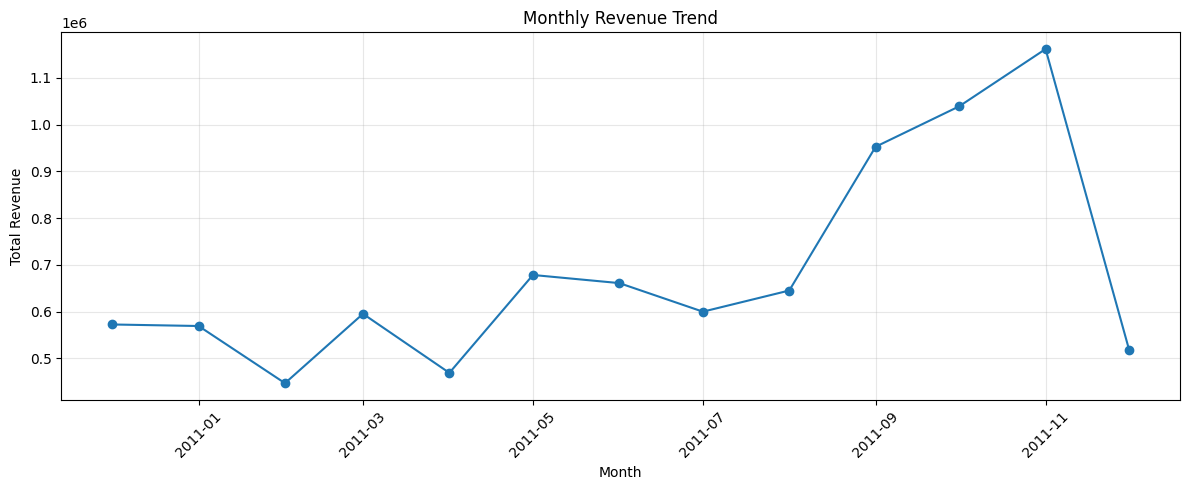

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["Month"],
    monthly_sales["TotalRevenue"],
    marker="o"
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [12]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Prepare monthly data
forecast_df = monthly_sales.copy()
forecast_df = forecast_df.sort_values("Month").reset_index(drop=True)

# Create time-based features
forecast_df["MonthNumber"] = range(len(forecast_df))
forecast_df["MonthOfYear"] = forecast_df["Month"].dt.month

# Keep chronological order: older months for training, newer months for testing
if len(forecast_df) < 6:
    print("Forecasting ke liye kam se kam 6 monthly records chahiye.")
else:
    split = int(len(forecast_df) * 0.8)

    X = forecast_df[["MonthNumber", "MonthOfYear"]]
    y = forecast_df["TotalRevenue"]

    X_train, X_test = X.iloc[:split], X.iloc[split:]
    y_train, y_test = y.iloc[:split], y.iloc[split:]

    model = RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    print("Test MAE:", mean_absolute_error(y_test, predictions))
    print("Actual vs Predicted Revenue:")
    print(pd.DataFrame({
        "Month": forecast_df["Month"].iloc[split:].values,
        "ActualRevenue": y_test.values,
        "PredictedRevenue": predictions
    }))

Test MAE: 282899.00185166654
Actual vs Predicted Revenue:
       Month  ActualRevenue  PredictedRevenue
0 2011-10-01     1039318.79     834246.374445
1 2011-11-01     1161817.38     833156.924295
2 2011-12-01      518192.79     833156.924295


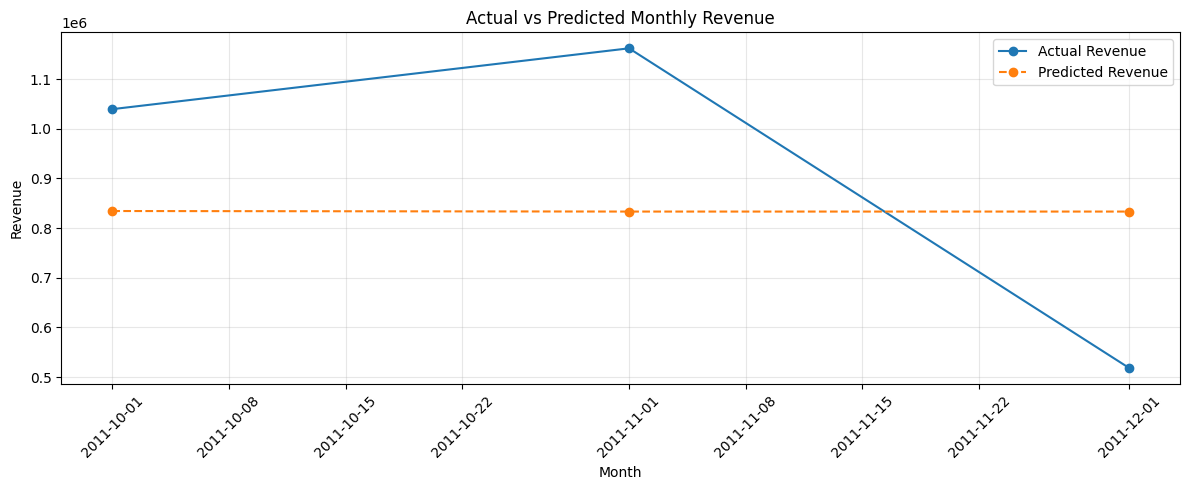

In [13]:
import matplotlib.pyplot as plt

if len(forecast_df) >= 6:
    results = pd.DataFrame({
        "Month": forecast_df["Month"].iloc[split:].values,
        "ActualRevenue": y_test.values,
        "PredictedRevenue": predictions
    })

    plt.figure(figsize=(12, 5))
    plt.plot(
        results["Month"], results["ActualRevenue"],
        marker="o", label="Actual Revenue"
    )
    plt.plot(
        results["Month"], results["PredictedRevenue"],
        marker="o", linestyle="--", label="Predicted Revenue"
    )

    plt.title("Actual vs Predicted Monthly Revenue")
    plt.xlabel("Month")
    plt.ylabel("Revenue")
    plt.xticks(rotation=45)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("Pehle kam se kam 6 monthly records chahiye.")

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    forecast_df["Month"],
    forecast_df["TotalRevenue"],
    marker="o",
    label="Historical Revenue"
)

plt.plot(
    future_df["Month"],
    future_df["PredictedRevenue"],
    marker="o",
    linestyle="--",
    label="Forecast Revenue"
)

plt.title("Historical Revenue vs Next 3 Months Forecast")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
import pandas as pd

# Use cleaned transaction data
customer_df = sales_df.copy()

# Exclude cancelled/return transactions for this customer analysis
customer_df = customer_df[
    (customer_df["Quantity"] > 0) &
    (customer_df["UnitPrice"] > 0)
].copy()

# Calculate a reference date after the latest transaction
reference_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

# Build customer-level RFM metrics
rfm = customer_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
).reset_index()

print("Customer records:", len(rfm))
display(rfm.head(10))

Customer records: 4338


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40
5,12352.0,36,8,2506.04
6,12353.0,204,1,89.00
7,12354.0,232,1,1079.40
8,12355.0,214,1,459.40
9,12356.0,23,3,2811.43


In [15]:
# Create 4 groups for each RFM metric
# Recency: lower days = better, so reverse the score
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: higher purchase count = better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: higher purchase value = better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Combine scores
rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str) +
    rfm["F_Score"].astype(str) +
    rfm["M_Score"].astype(str)
)

display(rfm.head(10))
print("\nRFM score distribution:")
print(rfm["RFM_Score"].value_counts().head(10))

,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,4,114
1,12347.0,2,7,4310.00,4,4,4,444
2,12348.0,75,4,1797.24,2,3,4,234
3,12349.0,19,1,1757.55,3,1,4,314
4,12350.0,310,1,334.40,1,1,2,112
5,12352.0,36,8,2506.04,3,4,4,344
6,12353.0,204,1,89.00,1,1,1,111
7,12354.0,232,1,1079.40,1,1,3,113
8,12355.0,214,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,3,3,4,334



RFM score distribution:
RFM_Score
444    478
111    303
344    222
121    188
112    170
333    163
233    158
211    148
433    129
122    129
Name: count, dtype: int64


In [16]:
def assign_segment(row):
    r = row["R_Score"]
    f = row["F_Score"]
    m = row["M_Score"]

    if r >= 3 and f >= 3 and m >= 3:
        return "Champions"
    elif r >= 2 and f >= 3:
        return "Loyal Customers"
    elif r >= 3 and f >= 2:
        return "Potential Loyalists"
    elif r <= 2 and f >= 2:
        return "At Risk"
    else:
        return "Needs Attention"

rfm["CustomerSegment"] = rfm.apply(assign_segment, axis=1)

print("Customer Segment Counts:")
print(rfm["CustomerSegment"].value_counts())

display(
    rfm.groupby("CustomerSegment")
    .agg(
        Customers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        TotalMonetary=("Monetary", "sum")
    )
    .round(2)
    .sort_values("Customers", ascending=False)
)

Customer Segment Counts:
CustomerSegment
Champions              1314
Needs Attention        1085
At Risk                 863
Loyal Customers         674
Potential Loyalists     402
Name: count, dtype: int64


,Customers,AvgRecency,AvgFrequency,TotalMonetary
CustomerSegment,,,,
Champions,1314,16.97,9.39,6494204.98
Needs Attention,1085,156.31,1.00,488432.90
At Risk,863,180.54,2.01,644646.36
Loyal Customers,674,65.52,3.97,876786.66
Potential Loyalists,402,23.81,1.74,407337.00


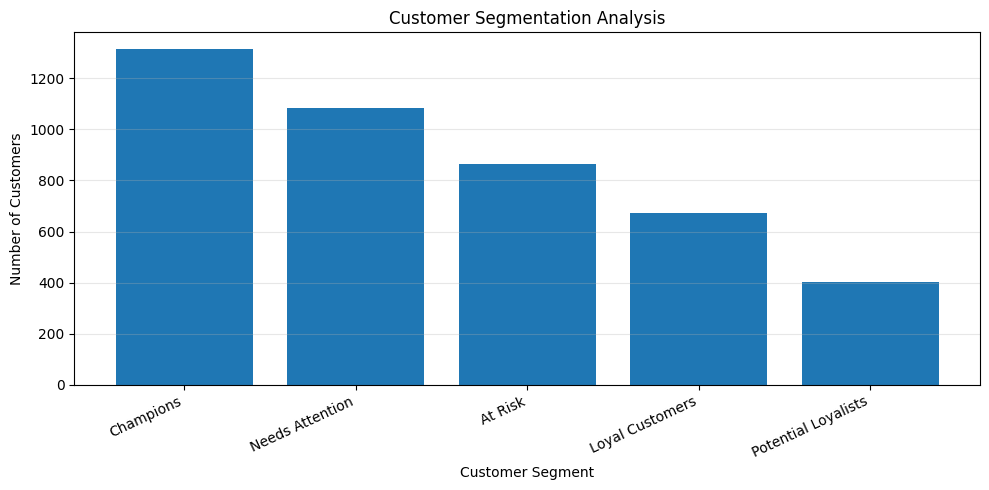

In [17]:
import matplotlib.pyplot as plt

# Chart 1: Number of customers in each segment
segment_counts = rfm["CustomerSegment"].value_counts()

plt.figure(figsize=(10, 5))
plt.bar(segment_counts.index, segment_counts.values)
plt.title("Customer Segmentation Analysis")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

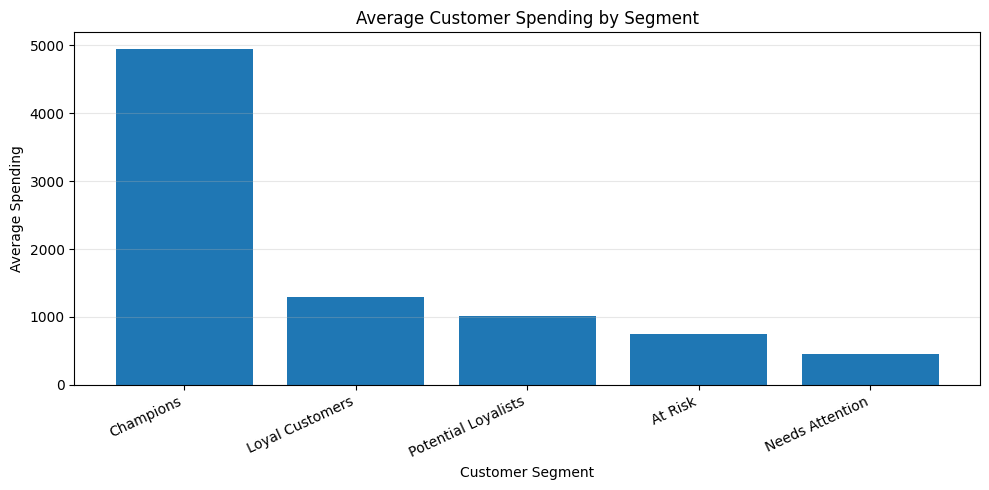

In [18]:
segment_spending = (
    rfm.groupby("CustomerSegment")["Monetary"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))
plt.bar(segment_spending.index, segment_spending.values)
plt.title("Average Customer Spending by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Spending")
plt.xticks(rotation=25, ha="right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

# Save customer-level segmentation
rfm.to_csv(
    output_folder / "customer_segments.csv",
    index=False
)

# Save summary for dashboard
segment_summary = (
    rfm.groupby("CustomerSegment", as_index=False)
    .agg(
        Customers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        TotalMonetary=("Monetary", "sum")
    )
    .round(2)
)

segment_summary.to_csv(
    output_folder / "customer_segment_summary.csv",
    index=False
)

print("Files saved successfully:")
print(output_folder / "customer_segments.csv")
print(output_folder / "customer_segment_summary.csv")

display(segment_summary)

Files saved successfully:
outputs\customer_segments.csv
outputs\customer_segment_summary.csv


,CustomerSegment,Customers,AvgRecency,AvgFrequency,TotalMonetary
0,At Risk,863,180.54,2.01,644646.36
1,Champions,1314,16.97,9.39,6494204.98
2,Loyal Customers,674,65.52,3.97,876786.66
3,Needs Attention,1085,156.31,1.00,488432.90
4,Potential Loyalists,402,23.81,1.74,407337.00


In [20]:
# Check segment totals
print("Total customers in RFM:", rfm["CustomerID"].nunique())
print("Total rows in RFM:", len(rfm))

print("\nMissing values:")
print(rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary", "CustomerSegment"]
].isnull().sum())

print("\nSegment summary:")
display(
    rfm.groupby("CustomerSegment")
    .agg(
        Customers=("CustomerID", "nunique"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgSpending=("Monetary", "mean")
    )
    .round(2)
)

Total customers in RFM: 4338
Total rows in RFM: 4338

Missing values:
CustomerID         0
Recency            0
Frequency          0
Monetary           0
CustomerSegment    0
dtype: int64

Segment summary:


,Customers,AvgRecency,AvgFrequency,AvgSpending
CustomerSegment,,,,
At Risk,863,180.54,2.01,746.98
Champions,1314,16.97,9.39,4942.32
Loyal Customers,674,65.52,3.97,1300.87
Needs Attention,1085,156.31,1.00,450.17
Potential Loyalists,402,23.81,1.74,1013.28


In [24]:
from pathlib import Path

files_to_check = [
    Path("outputs/customer_segments.csv"),
    Path("outputs/customer_segment_summary.csv")
]

for file in files_to_check:
    print(file, "->", "FOUND" if file.exists() else "NOT FOUND")

outputs\customer_segments.csv -> FOUND
outputs\customer_segment_summary.csv -> FOUND


In [25]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select RFM features
X = rfm[["Recency", "Frequency", "Monetary"]].copy()

# Reduce the effect of extreme values
X["Frequency"] = X["Frequency"].clip(
    upper=X["Frequency"].quantile(0.99)
)
X["Monetary"] = X["Monetary"].clip(
    upper=X["Monetary"].quantile(0.99)
)

# Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Train K-Means model
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(X_scaled)

print("K-Means Clustering Completed!")
print("\nCustomers in each cluster:")
print(rfm["Cluster"].value_counts().sort_index())

display(rfm.head())

K-Means Clustering Completed!

Customers in each cluster:
Cluster
0    2620
1     574
2    1035
3     109
Name: count, dtype: int64


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,CustomerSegment,Cluster
0,12346.0,326,1,77183.60,1,1,4,114,Needs Attention,3
1,12347.0,2,7,4310.00,4,4,4,444,Champions,1
2,12348.0,75,4,1797.24,2,3,4,234,Loyal Customers,0
3,12349.0,19,1,1757.55,3,1,4,314,Needs Attention,0
4,12350.0,310,1,334.40,1,1,2,112,Needs Attention,2


In [26]:
# Summarize each K-Means customer cluster
cluster_summary = (
    rfm.groupby("Cluster", as_index=False)
    .agg(
        Customers=("CustomerID", "count"),
        AvgRecency=("Recency", "mean"),
        AvgFrequency=("Frequency", "mean"),
        AvgMonetary=("Monetary", "mean")
    )
    .round(2)
)

display(cluster_summary)

,Cluster,Customers,AvgRecency,AvgFrequency,AvgMonetary
0,0,2620,48.46,2.74,914.23
1,1,574,22.30,10.58,4230.63
2,2,1035,250.89,1.51,441.67
3,3,109,18.29,34.03,33308.40


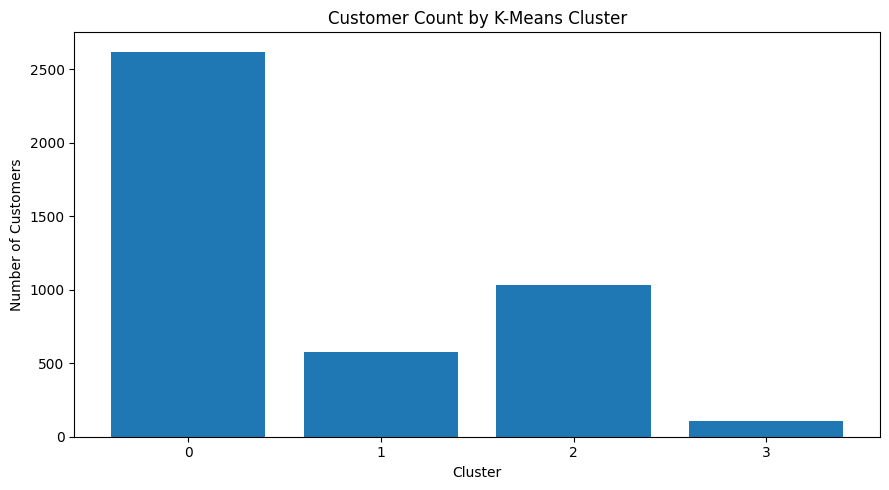

In [27]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(
    cluster_summary["Cluster"].astype(str),
    cluster_summary["Customers"]
)
plt.title("Customer Count by K-Means Cluster")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [28]:
from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

# Save customers with their K-Means cluster labels
rfm.to_csv(output_folder / "customer_clusters.csv", index=False)

# Save cluster-level summary
cluster_summary.to_csv(
    output_folder / "kmeans_cluster_summary.csv",
    index=False
)

print("K-Means files saved successfully:")
print(output_folder / "customer_clusters.csv")
print(output_folder / "kmeans_cluster_summary.csv")


K-Means files saved successfully:
outputs\customer_clusters.csv
outputs\kmeans_cluster_summary.csv


In [29]:
from pathlib import Path

files_to_check = [
    Path("outputs/customer_clusters.csv"),
    Path("outputs/kmeans_cluster_summary.csv")
]

for file in files_to_check:
    print(f"{file}: {'FOUND' if file.exists() else 'NOT FOUND'}")

outputs\customer_clusters.csv: FOUND
outputs\kmeans_cluster_summary.csv: FOUND


In [30]:
# Top Products Analysis

product_summary = (
    sales_df.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("TotalRevenue", ascending=False)
)

print("Top 10 Products by Revenue:")
display(product_summary.head(10))

Top 10 Products by Revenue:


,StockCode,Description,TotalQuantity,TotalRevenue,Transactions
2602,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
1318,22423,REGENCY CAKESTAND 3 TIER,12402,142592.95,1703
3459,85123A,WHITE HANGING HEART T-LIGHT HOLDER,36725,100448.15,1971
3444,85099B,JUMBO BAG RED RETROSPOT,46181,85220.78,1600
2100,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,195
3896,POST,POSTAGE,3120,77803.96,1099
2799,47566,PARTY BUNTING,15291,68844.33,1379
3278,84879,ASSORTED COLOUR BIRD ORNAMENT,35362,56580.34,1375
3894,M,Manual,7173,53779.93,253
2006,23084,RABBIT NIGHT LIGHT,27202,51346.20,801


In [31]:
# Top Products Analysis

product_summary = (
    sales_df.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        TotalQuantity=("Quantity", "sum"),
        TotalRevenue=("Revenue", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("TotalRevenue", ascending=False)
)

print("Top 10 Products by Revenue:")
display(product_summary.head(10))

Top 10 Products by Revenue:


,StockCode,Description,TotalQuantity,TotalRevenue,Transactions
2602,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,1
1318,22423,REGENCY CAKESTAND 3 TIER,12402,142592.95,1703
3459,85123A,WHITE HANGING HEART T-LIGHT HOLDER,36725,100448.15,1971
3444,85099B,JUMBO BAG RED RETROSPOT,46181,85220.78,1600
2100,23166,MEDIUM CERAMIC TOP STORAGE JAR,77916,81416.73,195
3896,POST,POSTAGE,3120,77803.96,1099
2799,47566,PARTY BUNTING,15291,68844.33,1379
3278,84879,ASSORTED COLOUR BIRD ORNAMENT,35362,56580.34,1375
3894,M,Manual,7173,53779.93,253
2006,23084,RABBIT NIGHT LIGHT,27202,51346.20,801


In [32]:
from pathlib import Path

output_folder = Path("outputs")
output_folder.mkdir(exist_ok=True)

product_summary.to_csv(
    output_folder / "top_products.csv",
    index=False
)

print("Top Products saved successfully!")
print("Rows:", len(product_summary))

Top Products saved successfully!
Rows: 3897


In [33]:
country_summary = (
    sales_df.groupby("Country", dropna=False)
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        Transactions=("InvoiceNo", "nunique")
    )
    .reset_index()
    .sort_values("TotalRevenue", ascending=False)
)

display(country_summary.head(10))

country_summary.to_csv(
    "outputs/country_sales_summary.csv",
    index=False
)

,Country,TotalRevenue,TotalQuantity,Transactions
35,United Kingdom,7308391.554,4256740,16646
23,Netherlands,285446.340,200361,94
10,EIRE,265545.900,140275,260
14,Germany,228867.140,119261,457
13,France,209024.050,111471,389
0,Australia,138521.310,83901,57
30,Spain,61577.110,27940,90
32,Switzerland,56443.950,30082,51
3,Belgium,41196.340,23237,98
31,Sweden,38378.330,36083,36


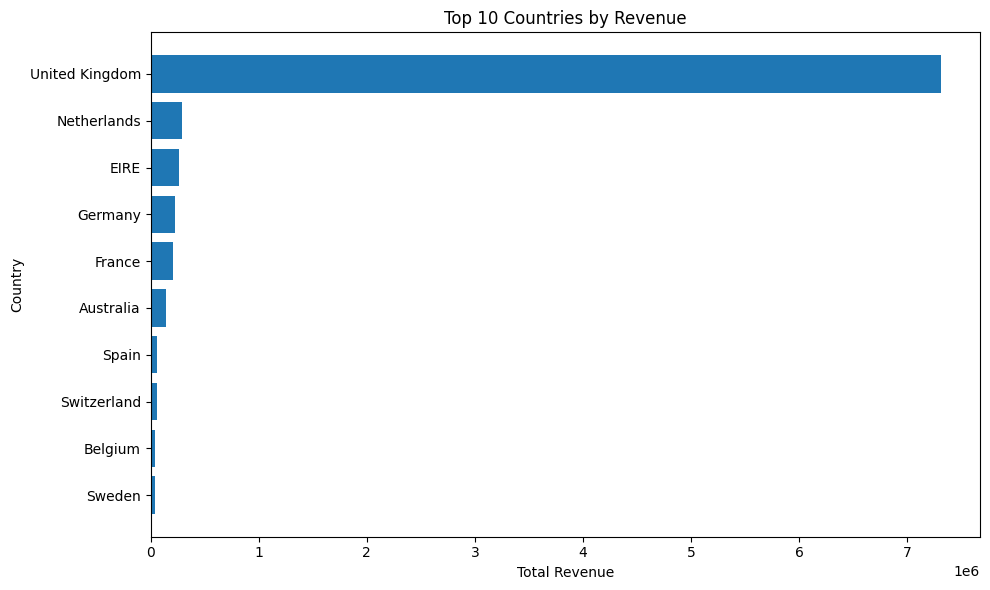

In [34]:
import matplotlib.pyplot as plt

top_countries = country_summary.head(10).copy()

plt.figure(figsize=(10, 6))
plt.barh(
    top_countries["Country"].astype(str).iloc[::-1],
    top_countries["TotalRevenue"].iloc[::-1]
)
plt.title("Top 10 Countries by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [35]:
from itertools import combinations
from collections import Counter

# Use invoice baskets containing distinct products
basket_data = sales_df[
    sales_df["InvoiceNo"].notna()
    & sales_df["StockCode"].notna()
].copy()

basket_data["StockCode"] = basket_data["StockCode"].astype(str)

invoice_baskets = (
    basket_data.groupby("InvoiceNo")["StockCode"]
    .apply(lambda x: sorted(set(x)))
)

pair_counts = Counter()

for products in invoice_baskets:
    if len(products) > 1:
        pair_counts.update(combinations(products, 2))

recommendation_rows = []

for (product_a, product_b), count in pair_counts.items():
    recommendation_rows.append({
        "Product": product_a,
        "RecommendedProduct": product_b,
        "CoPurchaseCount": count
    })
    recommendation_rows.append({
        "Product": product_b,
        "RecommendedProduct": product_a,
        "CoPurchaseCount": count
    })

recommendations_df = pd.DataFrame(recommendation_rows)

if not recommendations_df.empty:
    recommendations_df = recommendations_df.sort_values(
        ["Product", "CoPurchaseCount"],
        ascending=[True, False]
    )

display(recommendations_df.head(10))

,Product,RecommendedProduct,CoPurchaseCount
106924,10002,22383,13
106894,10002,20725,11
192,10002,21731,8
194,10002,21791,8
106896,10002,20727,8
106960,10002,85123A,8
362220,10002,22551,8
362222,10002,22554,8
368398,10002,22367,8
374872,10002,21915,8


In [36]:
recommendations_df.to_csv(
    "outputs/product_recommendations.csv",
    index=False
)

print("Product recommendations saved!")
print("Total recommendation rows:", len(recommendations_df))

Product recommendations saved!
Total recommendation rows: 4440366


In [37]:
from pathlib import Path

required_files = [
    "customer_segments.csv",
    "customer_segment_summary.csv",
    "customer_clusters.csv",
    "kmeans_cluster_summary.csv",
    "top_products.csv",
    "country_sales_summary.csv",
    "product_recommendations.csv"
]

for filename in required_files:
    path = Path("outputs") / filename
    print(f"{filename}: {'FOUND' if path.exists() else 'MISSING'}")

customer_segments.csv: FOUND
customer_segment_summary.csv: FOUND
customer_clusters.csv: FOUND
kmeans_cluster_summary.csv: FOUND
top_products.csv: FOUND
country_sales_summary.csv: FOUND
product_recommendations.csv: FOUND


In [38]:
print("MONTHLY SALES DATA:", monthly_sales.shape)
print("CUSTOMER RFM DATA:", rfm.shape)
print("TOP PRODUCTS DATA:", product_summary.shape)
print("COUNTRY SUMMARY:", country_summary.shape)
print("RECOMMENDATIONS DATA:", recommendations_df.shape)

print("\nPROJECT ANALYSIS CHECK COMPLETED")

MONTHLY SALES DATA: (13, 4)
CUSTOMER RFM DATA: (4338, 10)
TOP PRODUCTS DATA: (3897, 5)
COUNTRY SUMMARY: (37, 4)
RECOMMENDATIONS DATA: (4440366, 3)

PROJECT ANALYSIS CHECK COMPLETED


In [39]:
from pathlib import Path

output_dir = Path(r"C:\EcommerceDashboard")
output_dir.mkdir(parents=True, exist_ok=True)

print("CSV save folder:", output_dir)

CSV save folder: C:\EcommerceDashboard


In [40]:
print(df.columns.tolist())
print(df.head())

['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom    22.00  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  


In [41]:
print([name for name, obj in globals().items()
       if hasattr(obj, "columns") and hasattr(obj, "head")])

['_', '__', '___', 'df', '_1', '_2', 'ml_df', 'model_df', '_9', 'sales_df', 'monthly_sales', '_10', 'forecast_df', 'X', 'X_train', 'X_test', 'results', 'customer_df', 'rfm', 'segment_summary', 'cluster_summary', 'product_summary', 'country_summary', 'top_countries', 'basket_data', 'recommendations_df']


In [42]:
from pathlib import Path

out = Path(r"C:\EcommerceDashboard")
out.mkdir(parents=True, exist_ok=True)

segment_summary.to_csv(out / "cluster_summary.csv", index=False)
cluster_summary.to_csv(out / "customer_clusters.csv", index=False)
customer_df.to_csv(out / "customer_segments.csv", index=False)

print("Saved files:")
print(list(out.glob("*.csv")))

Saved files:
[WindowsPath('C:/EcommerceDashboard/cluster_summary.csv'), WindowsPath('C:/EcommerceDashboard/customer_clusters.csv'), WindowsPath('C:/EcommerceDashboard/customer_segments.csv')]


In [43]:
from pathlib import Path
print([f.name for f in Path(r"C:\EcommerceDashboard").glob("*.csv")])

['cluster_summary.csv', 'customer_clusters.csv', 'customer_segments.csv']


In [44]:
print("customer_df columns:", customer_df.columns.tolist())
print("segment_summary columns:", segment_summary.columns.tolist())
print("cluster_summary columns:", cluster_summary.columns.tolist())

customer_df columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'Month']
segment_summary columns: ['CustomerSegment', 'Customers', 'AvgRecency', 'AvgFrequency', 'TotalMonetary']
cluster_summary columns: ['Cluster', 'Customers', 'AvgRecency', 'AvgFrequency', 'AvgMonetary']


In [45]:
from pathlib import Path

out = Path(r"C:\EcommerceDashboard")
print("customer_segments exists:", (out / "customer_segments.csv").exists())
print("CSV files:", [f.name for f in out.glob("*.csv")])

customer_segments exists: True
CSV files: ['cluster_summary.csv', 'customer_clusters.csv', 'customer_segments.csv']


In [52]:
import pandas as pd

df_check = pd.read_csv(r"C:\EcommerceDashboard\customer_segments.csv")

print("Columns:", df_check.columns.tolist())
print(df_check.head(3))

Columns: ['CustomerID', 'Revenue', 'Orders', 'Segment']
   CustomerID   Revenue  Orders     Segment
0     12346.0  77183.60       1  High Value
1     12347.0   4310.00       7  High Value
2     12348.0   1797.24       4  High Value


In [53]:
import pandas as pd
from pathlib import Path

out = Path(r"C:\EcommerceDashboard")

df = pd.read_csv(out / "customer_segments.csv")

df["Revenue"] = pd.to_numeric(df["Revenue"], errors="coerce").fillna(0)

customers = df.groupby("CustomerID", dropna=True).agg(
    Revenue=("Revenue", "sum"),
    Orders=("InvoiceNo", "nunique")
).reset_index()

customers["Segment"] = pd.qcut(
    customers["Revenue"].rank(method="first"),
    3,
    labels=["Low Value", "Medium Value", "High Value"]
)

customers.to_csv(out / "customer_segments.csv", index=False)

print(customers.head())
print(customers["Segment"].value_counts())

KeyError: "Label(s) ['InvoiceNo'] do not exist"

In [54]:
from pathlib import Path

folder = Path(r"C:\EcommerceDashboard")

print("Project folder files:")
for file in folder.iterdir():
    if file.is_file():
        print(file.name)

Project folder files:
app.py
cluster_summary.csv
customer_clusters.csv
customer_segments.csv
ecommerce.db
python
Untitled.ipynb


In [55]:
import sqlite3

db_path = r"C:\EcommerceDashboard\ecommerce.db"

conn = sqlite3.connect(db_path)

tables = conn.execute("""
    SELECT name
    FROM sqlite_master
    WHERE type = 'table'
""").fetchall()

print("Database tables:")
for table in tables:
    print(table[0])

conn.close()

Database tables:
inventory
sqlite_sequence


In [56]:
import pandas as pd
from pathlib import Path

folder = Path(r"C:\EcommerceDashboard")

for name in ["customer_segments.csv", "customer_clusters.csv", "cluster_summary.csv"]:
    file_path = folder / name
    if file_path.exists():
        df = pd.read_csv(file_path)
        print(f"\n--- {name} ---")
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))


--- customer_segments.csv ---
Columns: ['CustomerID', 'Revenue', 'Orders', 'Segment']
 CustomerID  Revenue  Orders    Segment
    12346.0 77183.60       1 High Value
    12347.0  4310.00       7 High Value
    12348.0  1797.24       4 High Value

--- customer_clusters.csv ---
Columns: ['Cluster', 'Customers', 'AvgRecency', 'AvgFrequency', 'AvgMonetary']
 Cluster  Customers  AvgRecency  AvgFrequency  AvgMonetary
       0       2620       48.46          2.74       914.23
       1        574       22.30         10.58      4230.63
       2       1035      250.89          1.51       441.67

--- cluster_summary.csv ---
Columns: ['CustomerSegment', 'Customers', 'AvgRecency', 'AvgFrequency', 'TotalMonetary']
CustomerSegment  Customers  AvgRecency  AvgFrequency  TotalMonetary
        At Risk        863      180.54          2.01      644646.36
      Champions       1314       16.97          9.39     6494204.98
Loyal Customers        674       65.52          3.97      876786.66


In [57]:
from pathlib import Path

for p in Path(r"C:\EcommerceDashboard").glob("*"):
    print(p.name)

.ipynb_checkpoints
app.py
cluster_summary.csv
customer_clusters.csv
customer_segments.csv
data
ecommerce.db
outputs
python
Untitled.ipynb


In [58]:
import os

print("Current folder:", os.getcwd())
print("Data folder exists:", os.path.exists("data"))
print("Dataset exists:", os.path.exists("data/ecommerce_cleaned.csv"))

print("\nFiles in data folder:")
if os.path.exists("data"):
    print(os.listdir("data"))

Current folder: C:\EcommerceDashboard
Data folder exists: True
Dataset exists: True

Files in data folder:
['ecommerce_cleaned.csv']


In [59]:
import shutil
from pathlib import Path

source = Path("data/ecommerce_cleaned.csv")
destination = Path(r"C:\EcommerceDashboard\sales_data.csv")

shutil.copy2(source, destination)

print("Dataset copied:", destination.exists())
print("Saved location:", destination)

Dataset copied: True
Saved location: C:\EcommerceDashboard\sales_data.csv


In [60]:
import pandas as pd

df = pd.read_csv(
    r"C:\EcommerceDashboard\sales_data.csv",
    low_memory=False
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head(2))

Shape: (530104, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
  InvoiceNo StockCode                         Description  Quantity  \
0    536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                 WHITE METAL LANTERN         6   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  


In [61]:
import pandas as pd

df = pd.read_csv(
    r"C:\EcommerceDashboard\sales_data.csv",
    low_memory=False
)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head(2))

Shape: (530104, 9)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']
  InvoiceNo StockCode                         Description  Quantity  \
0    536365    85123A  WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                 WHITE METAL LANTERN         6   

           InvoiceDate  UnitPrice  CustomerID         Country  Revenue  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom    15.30  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom    20.34  
